In [3]:
import pandas as pd
import re

from sklearn.feature_extraction.text import TfidfVectorizer

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
# Load dataset
df = pd.read_csv("../data/IMDB Dataset.csv")

# Remove duplicate reviews
df = df.drop_duplicates()

# Remove HTML tags
def clean_html(text):
    text = re.sub(r"<.*?>", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

# Convert to lowercase
df["cleaned_review"] = df["review"].apply(clean_html).str.lower()

# Remove punctuation and special characters
def remove_special_characters(text):
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

df["cleaned_review"] = df["cleaned_review"].apply(
    remove_special_characters
)

print("Dataset loaded and cleaned successfully!")
print("Dataset shape:", df.shape)

df[["cleaned_review", "sentiment"]].head()

Dataset loaded and cleaned successfully!
Dataset shape: (49582, 3)


,cleaned_review,sentiment
0,one of the other reviewers has mentioned that ...,positive
1,a wonderful little production the filming tech...,positive
2,i thought this was a wonderful way to spend ti...,positive
3,basically there s a family where a little boy ...,negative
4,petter mattei s love in the time of money is a...,positive


In [5]:
documents = [
    "the movie was good",
    "the movie was excellent",
    "the movie was bad"
]

In [6]:
from sklearn.feature_extraction.text import CountVectorizer

documents = [
    "the movie was good",
    "the movie was excellent",
    "the movie was bad"
]

vectorizer = CountVectorizer()

tf_matrix = vectorizer.fit_transform(documents)

tf_df = pd.DataFrame(
    tf_matrix.toarray(),
    columns=vectorizer.get_feature_names_out()
)

print(tf_df)

   bad  excellent  good  movie  the  was
0    0          0     1      1    1    1
1    0          1     0      1    1    1
2    1          0     0      1    1    1


In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer

documents = [
    "the movie was good",
    "the movie was excellent",
    "the movie was bad"
]

vectorizer = TfidfVectorizer()

tfidf_matrix = vectorizer.fit_transform(documents)

idf_df = pd.DataFrame({
    "Word": vectorizer.get_feature_names_out(),
    "IDF Score": vectorizer.idf_
})

print(idf_df)

        Word  IDF Score
0        bad   1.693147
1  excellent   1.693147
2       good   1.693147
3      movie   1.000000
4        the   1.000000
5        was   1.000000


In [8]:
# Convert TF-IDF matrix into a DataFrame
tfidf_df = pd.DataFrame(
    tfidf_matrix.toarray(),
    columns=vectorizer.get_feature_names_out()
)

print("TF-IDF Matrix:")
print(tfidf_df.round(3))

TF-IDF Matrix:
     bad  excellent   good  movie    the    was
0  0.000      0.000  0.699  0.413  0.413  0.413
1  0.000      0.699  0.000  0.413  0.413  0.413
2  0.699      0.000  0.000  0.413  0.413  0.413


In [9]:
# Create TF-IDF vectorizer
tfidf_vectorizer = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95
)

print("TF-IDF vectorizer created successfully!")

TF-IDF vectorizer created successfully!


In [10]:
from sklearn.model_selection import train_test_split

# Separate input reviews and target labels
X = df["cleaned_review"]
y = df["sentiment"]

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Dataset split completed!")

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

Dataset split completed!

Training samples: 39665
Testing samples: 9917


In [11]:
print("Training sentiment distribution:")
print(y_train.value_counts())

print("\nTesting sentiment distribution:")
print(y_test.value_counts())

Training sentiment distribution:
sentiment
positive    19907
negative    19758
Name: count, dtype: int64

Testing sentiment distribution:
sentiment
positive    4977
negative    4940
Name: count, dtype: int64


In [12]:
# Fit TF-IDF on training data
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)

print("Training TF-IDF transformation completed!")

print("Training matrix shape:", X_train_tfidf.shape)

Training TF-IDF transformation completed!
Training matrix shape: (39665, 10000)


In [13]:
# Transform testing data using the fitted vectorizer
X_test_tfidf = tfidf_vectorizer.transform(X_test)

print("Testing TF-IDF transformation completed!")

print("Testing matrix shape:", X_test_tfidf.shape)

Testing TF-IDF transformation completed!
Testing matrix shape: (9917, 10000)


In [14]:
print("Training matrix shape:", X_train_tfidf.shape)
print("Testing matrix shape:", X_test_tfidf.shape)

print("\nNumber of TF-IDF features:",
      len(tfidf_vectorizer.get_feature_names_out()))

print("\nFirst 20 features:")
print(tfidf_vectorizer.get_feature_names_out()[:20])

Training matrix shape: (39665, 10000)
Testing matrix shape: (9917, 10000)

Number of TF-IDF features: 10000

First 20 features:
['00' '000' '10' '10 10' '10 for' '10 minutes' '10 out' '10 stars'
 '10 years' '100' '11' '12' '13' '14' '15' '15 minutes' '16' '17' '18'
 '1930']


In [15]:
print("Training matrix type:", type(X_train_tfidf))

print("Total possible values:",
      X_train_tfidf.shape[0] * X_train_tfidf.shape[1])

print("Non-zero values:", X_train_tfidf.nnz)

print("Matrix sparsity:",
      round(
          100 * (1 - X_train_tfidf.nnz /
                (X_train_tfidf.shape[0] * X_train_tfidf.shape[1])),
          2
      ), "%")

Training matrix type: <class 'scipy.sparse._csr.csr_matrix'>
Total possible values: 396650000
Non-zero values: 7246829
Matrix sparsity: 98.17 %


In [16]:
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("Model training libraries imported successfully!")

Model training libraries imported successfully!


In [17]:
# Create Logistic Regression model
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

print("Logistic Regression model created!")

Logistic Regression model created!


In [18]:
# Train Logistic Regression model
lr_model.fit(X_train_tfidf, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [19]:
# Predict sentiment for testing reviews
y_pred_lr = lr_model.predict(X_test_tfidf)

print("Predictions completed!")

print("\nFirst 10 actual labels:")
print(y_test.iloc[:10].tolist())

print("\nFirst 10 predicted labels:")
print(y_pred_lr[:10].tolist())

Predictions completed!

First 10 actual labels:
['negative', 'positive', 'positive', 'negative', 'negative', 'positive', 'negative', 'negative', 'positive', 'negative']

First 10 predicted labels:
['negative', 'positive', 'positive', 'negative', 'negative', 'positive', 'negative', 'negative', 'positive', 'negative']


In [20]:
# Calculate accuracy
lr_accuracy = accuracy_score(y_test, y_pred_lr)

print("Logistic Regression Accuracy:",
      round(lr_accuracy * 100, 2), "%")

Logistic Regression Accuracy: 90.16 %


In [21]:
print("Logistic Regression - Classification Report")

print(
    classification_report(
        y_test,
        y_pred_lr
    )
)

Logistic Regression - Classification Report
              precision    recall  f1-score   support

    negative       0.91      0.89      0.90      4940
    positive       0.89      0.92      0.90      4977

    accuracy                           0.90      9917
   macro avg       0.90      0.90      0.90      9917
weighted avg       0.90      0.90      0.90      9917



In [22]:
cm_lr = confusion_matrix(y_test, y_pred_lr)

print("Confusion Matrix:")
print(cm_lr)

Confusion Matrix:
[[4385  555]
 [ 421 4556]]


In [23]:
from sklearn.naive_bayes import MultinomialNB

# Create Multinomial Naive Bayes model
nb_model = MultinomialNB()

print("Multinomial Naive Bayes model created!")

Multinomial Naive Bayes model created!


In [24]:
# Train the Naive Bayes model
nb_model.fit(X_train_tfidf, y_train)

print("Naive Bayes training completed!")

Naive Bayes training completed!


In [25]:
y_pred_nb = nb_model.predict(X_test_tfidf)

print("Naive Bayes predictions completed!")

Naive Bayes predictions completed!


In [26]:
nb_accuracy = accuracy_score(y_test, y_pred_nb)

print("Naive Bayes Accuracy:", round(nb_accuracy * 100, 2), "%")

Naive Bayes Accuracy: 86.77 %


In [27]:
print("Multinomial Naive Bayes - Classification Report")
print(classification_report(y_test, y_pred_nb))

Multinomial Naive Bayes - Classification Report
              precision    recall  f1-score   support

    negative       0.88      0.85      0.87      4940
    positive       0.86      0.88      0.87      4977

    accuracy                           0.87      9917
   macro avg       0.87      0.87      0.87      9917
weighted avg       0.87      0.87      0.87      9917



In [28]:
cm_nb = confusion_matrix(y_test, y_pred_nb)

print("Naive Bayes Confusion Matrix:")
print(cm_nb)

Naive Bayes Confusion Matrix:
[[4212  728]
 [ 584 4393]]


In [29]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Multinomial Naive Bayes"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_nb)
    ],
    "Weighted F1-Score": [
        0.90,
        0.87
    ]
})

print(results)

                     Model  Accuracy  Weighted F1-Score
0      Logistic Regression  0.901583               0.90
1  Multinomial Naive Bayes  0.867702               0.87


In [30]:
from sklearn.metrics import f1_score

results["Weighted F1-Score"] = [
    f1_score(y_test, y_pred_lr, average="weighted"),
    f1_score(y_test, y_pred_nb, average="weighted")
]

results["Accuracy"] = results["Accuracy"] * 100
results["Weighted F1-Score"] = results["Weighted F1-Score"] * 100

print(results.round(2))

                     Model  Accuracy  Weighted F1-Score
0      Logistic Regression     90.16              90.16
1  Multinomial Naive Bayes     86.77              86.77


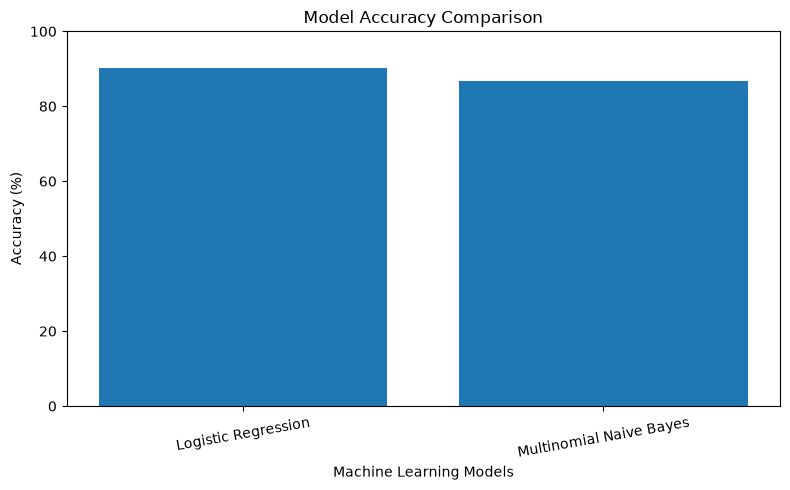

In [31]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    results["Model"],
    results["Accuracy"]
)

plt.title("Model Accuracy Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

plt.xticks(rotation=10)
plt.tight_layout()

plt.show()

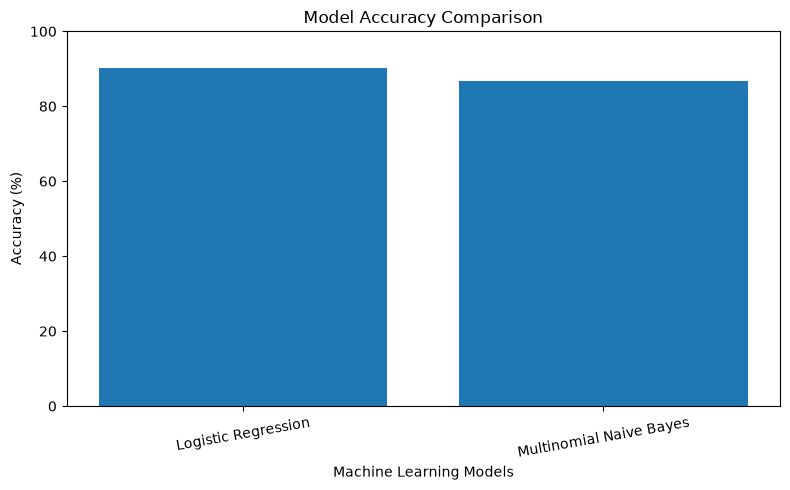

Model comparison chart saved successfully!


In [32]:
plt.figure(figsize=(8, 5))

plt.bar(
    results["Model"],
    results["Accuracy"]
)

plt.title("Model Accuracy Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

plt.xticks(rotation=10)
plt.tight_layout()

plt.savefig(
    "../reports/figures/model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Model comparison chart saved successfully!")

In [33]:
from sklearn.metrics import roc_auc_score, roc_curve

In [34]:
y_prob_lr = lr_model.predict_proba(X_test_tfidf)[:, 1]

roc_auc_lr = roc_auc_score(y_test, y_prob_lr)

print("Logistic Regression ROC-AUC:", round(roc_auc_lr, 4))

Logistic Regression ROC-AUC: 0.9638


In [35]:
y_prob_nb = nb_model.predict_proba(X_test_tfidf)[:, 1]

roc_auc_nb = roc_auc_score(y_test, y_prob_nb)

print("Naive Bayes ROC-AUC:", round(roc_auc_nb, 4))

Naive Bayes ROC-AUC: 0.9413


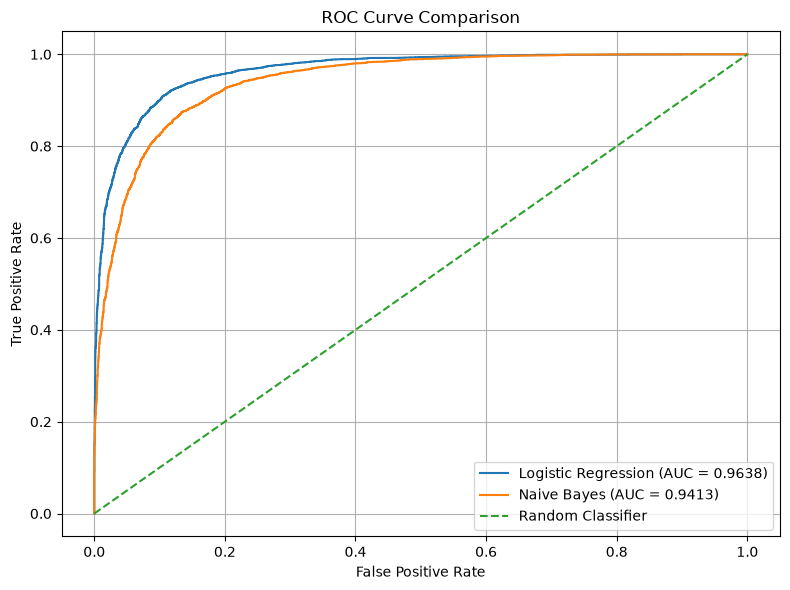

In [36]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

fpr_lr, tpr_lr, _ = roc_curve(
    y_test, y_prob_lr, pos_label="positive"
)

fpr_nb, tpr_nb, _ = roc_curve(
    y_test, y_prob_nb, pos_label="positive"
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_lr,
    tpr_lr,
    label=f"Logistic Regression (AUC = {roc_auc_lr:.4f})"
)

plt.plot(
    fpr_nb,
    tpr_nb,
    label=f"Naive Bayes (AUC = {roc_auc_nb:.4f})"
)

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.title("ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.legend()
plt.grid()
plt.tight_layout()

plt.show()

In [37]:
plt.savefig(
    "../reports/figures/roc_curve_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

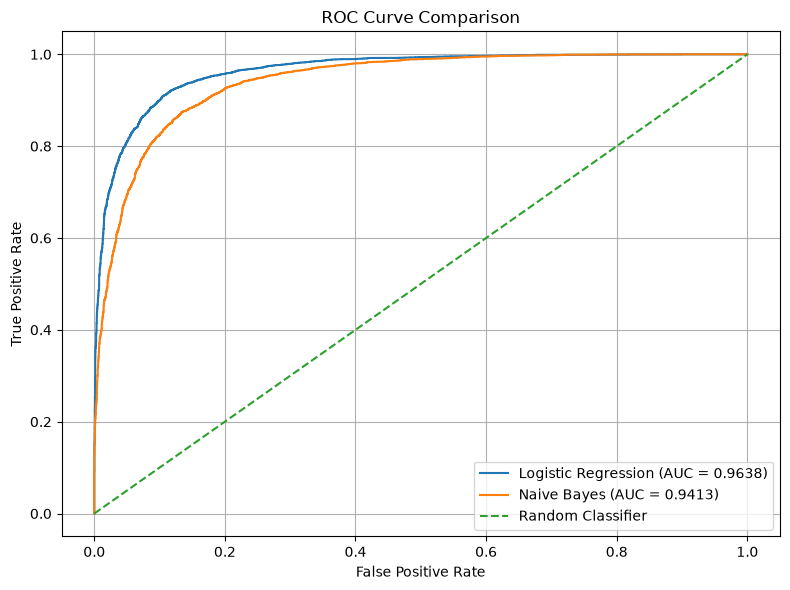

ROC curve comparison saved successfully!


In [38]:
plt.figure(figsize=(8, 6))

plt.plot(
    fpr_lr,
    tpr_lr,
    label=f"Logistic Regression (AUC = {roc_auc_lr:.4f})"
)

plt.plot(
    fpr_nb,
    tpr_nb,
    label=f"Naive Bayes (AUC = {roc_auc_nb:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title("ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.legend()
plt.grid()
plt.tight_layout()

# Save the figure
plt.savefig(
    "../reports/figures/roc_curve_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("ROC curve comparison saved successfully!")

In [39]:
from sklearn.metrics import precision_recall_curve, average_precision_score

In [40]:
precision_lr, recall_lr, _ = precision_recall_curve(
    y_test,
    y_prob_lr,
    pos_label="positive"
)

pr_auc_lr = average_precision_score(
    y_test,
    y_prob_lr,
    pos_label="positive"
)

print("Logistic Regression PR-AUC:", round(pr_auc_lr, 4))

Logistic Regression PR-AUC: 0.9639


In [41]:
precision_nb, recall_nb, _ = precision_recall_curve(
    y_test,
    y_prob_nb,
    pos_label="positive"
)

pr_auc_nb = average_precision_score(
    y_test,
    y_prob_nb,
    pos_label="positive"
)

print("Naive Bayes PR-AUC:", round(pr_auc_nb, 4))

Naive Bayes PR-AUC: 0.9391


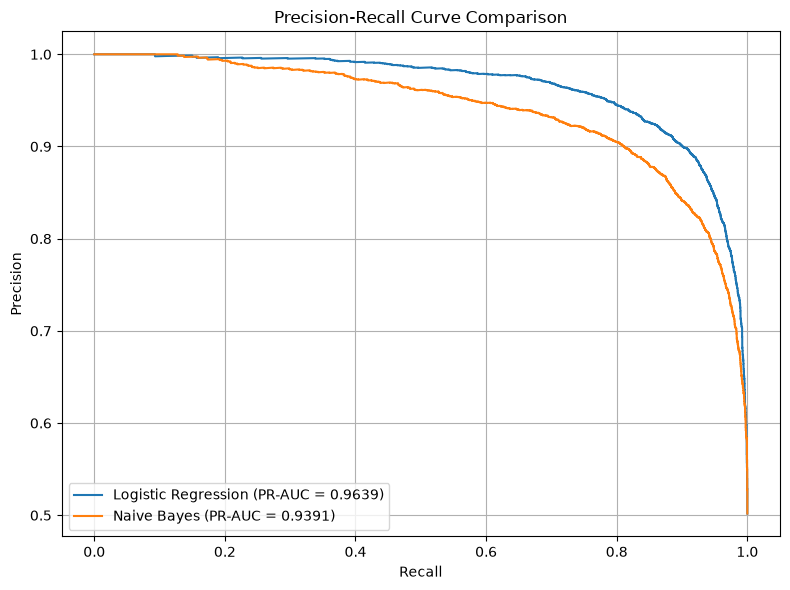

Precision-Recall curve saved successfully!


In [42]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.plot(
    recall_lr,
    precision_lr,
    label=f"Logistic Regression (PR-AUC = {pr_auc_lr:.4f})"
)

plt.plot(
    recall_nb,
    precision_nb,
    label=f"Naive Bayes (PR-AUC = {pr_auc_nb:.4f})"
)

plt.title("Precision-Recall Curve Comparison")
plt.xlabel("Recall")
plt.ylabel("Precision")

plt.legend()
plt.grid()
plt.tight_layout()

plt.savefig(
    "../reports/figures/precision_recall_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Precision-Recall curve saved successfully!")

In [43]:
import pandas as pd

# Get feature names from TF-IDF vectorizer
feature_names = tfidf_vectorizer.get_feature_names_out()

# Get Logistic Regression coefficients
coefficients = lr_model.coef_[0]

# Create a DataFrame
feature_importance = pd.DataFrame({
    "Word": feature_names,
    "Coefficient": coefficients
})

print("Feature importance data created!")
print(feature_importance.shape)

Feature importance data created!
(10000, 2)


In [44]:
# Top 15 positive words
top_positive = feature_importance.sort_values(
    by="Coefficient",
    ascending=False
).head(15)

# Top 15 negative words
top_negative = feature_importance.sort_values(
    by="Coefficient",
    ascending=True
).head(15)

print("Top 15 Positive Words:")
print(top_positive.to_string(index=False))

print("\nTop 15 Negative Words:")
print(top_negative.to_string(index=False))

Top 15 Positive Words:
     Word  Coefficient
    great     7.431890
excellent     6.398794
  perfect     5.380074
  amazing     4.911922
wonderful     4.891111
brilliant     4.276966
    today     4.054432
    loved     3.886405
      fun     3.866917
hilarious     3.777674
     best     3.757064
   superb     3.687807
enjoyable     3.665447
 the best     3.561770
     love     3.439334

Top 15 Negative Words:
     Word  Coefficient
    worst    -8.228416
    awful    -7.663776
      bad    -7.661926
   boring    -6.832084
     poor    -6.254255
the worst    -6.196053
 terrible    -5.908516
    waste    -5.858203
  nothing    -4.768906
    worse    -4.738831
     dull    -4.710713
 horrible    -4.709032
   poorly    -4.679021
   stupid    -4.364188
 annoying    -4.332207


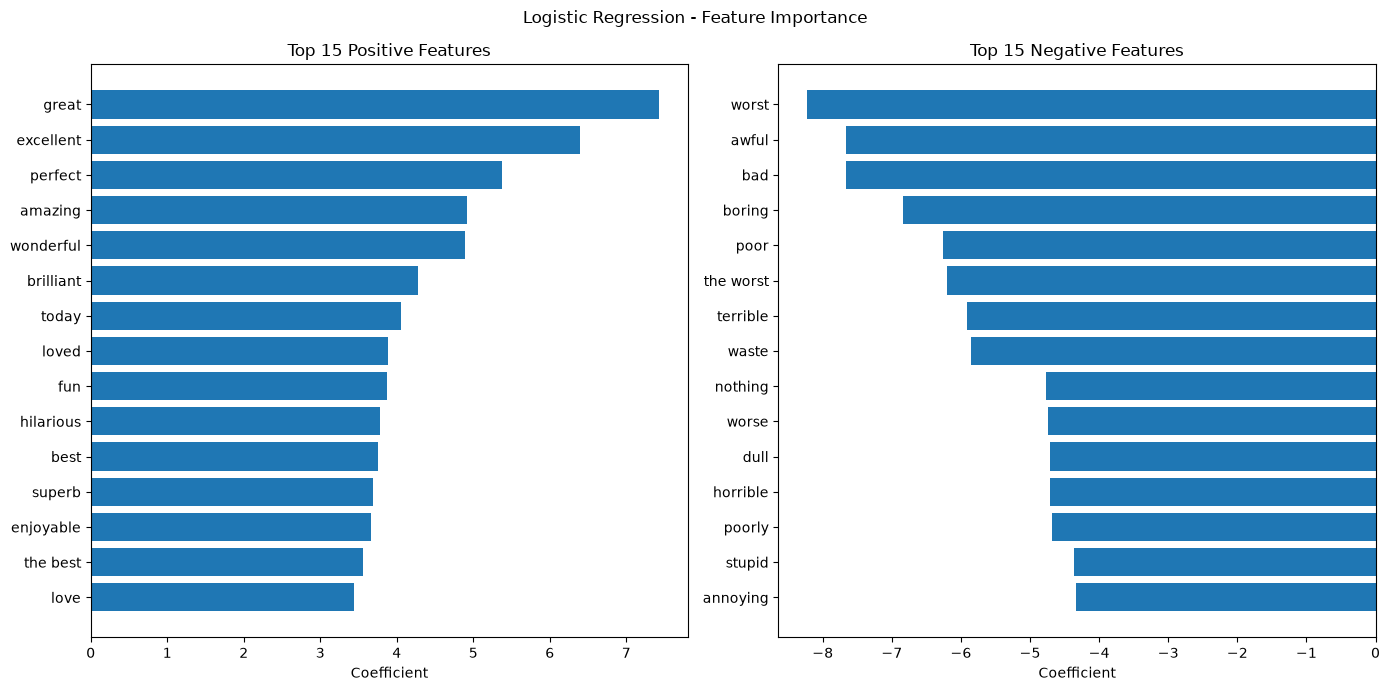

Feature importance chart saved successfully!


In [45]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

# Positive features
axes[0].barh(
    top_positive["Word"][::-1],
    top_positive["Coefficient"][::-1]
)
axes[0].set_title("Top 15 Positive Features")
axes[0].set_xlabel("Coefficient")

# Negative features
axes[1].barh(
    top_negative["Word"][::-1],
    top_negative["Coefficient"][::-1]
)
axes[1].set_title("Top 15 Negative Features")
axes[1].set_xlabel("Coefficient")

plt.suptitle("Logistic Regression - Feature Importance")
plt.tight_layout()

plt.savefig(
    "../reports/figures/feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Feature importance chart saved successfully!")

In [46]:
import joblib

print("Joblib imported successfully!")

Joblib imported successfully!


In [47]:
# Save Logistic Regression model
joblib.dump(
    lr_model,
    "../models/best_sentiment_model.pkl"
)

# Save TF-IDF vectorizer
joblib.dump(
    tfidf_vectorizer,
    "../models/tfidf_vectorizer.pkl"
)

print("Model and vectorizer saved successfully!")

Model and vectorizer saved successfully!
